In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("solar_system.csv")
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [3]:
df.shape # 20 rows and 11 columns

(20, 11)

In [4]:
df.head(5)

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [5]:
df.tail(5)

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [6]:
df.iloc[:, 0]

0                  Mass (10^24kg)
1                   Diameter (km)
2                Density (kg/m^3)
3                 Gravity (m/s^2)
4          Escape Velocity (km/s)
5         Rotation Period (hours)
6           Length of Day (hours)
7     Distance from Sun (10^6 km)
8            Perihelion (10^6 km)
9              Aphelion (10^6 km)
10          Orbital Period (days)
11        Orbital Velocity (km/s)
12      Orbital Inclination (deg)
13           Orbital Eccentricity
14       Obliquity to Orbit (deg)
15           Mean Temperature (C)
16        Surface Pressure (bars)
17                Number of Moons
18                   Ring System?
19         Global Magnetic Field?
Name: Attribute, dtype: str

In [7]:
orbital_period = df.iloc[10, 1:].astype(float)
perihelion = df.iloc[8, 1:].astype(float) # perihelion is the point of an object's motion where it is closest to the sun
aphelion = df.iloc[9, 1:].astype(float) # Aphelion is the point of an object's motion where it is furthest from the sun
# Semi major axis is the midway point between the aphelion and perihelion of an object's orbit.

In [8]:
semi_major_axis = (perihelion + aphelion) / 2

In [9]:
new_row_data = ["Semi-major Axis (10^6 km)"] + list(semi_major_axis)
new_row = pd.Series(new_row_data, index=df.columns)
df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

In [10]:
print(df.shape) # 21 rows and 11 columns

(21, 11)


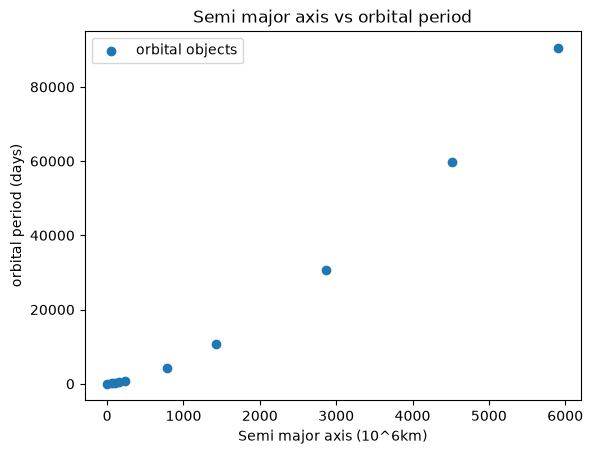

In [11]:
semimajoraxis = df.iloc[20, 1:].astype(float)
orbitalperiod = df.iloc[10, 1:].astype(float)
plt.figure()
plt.scatter(semimajoraxis, orbitalperiod, label = "orbital objects")
plt.title("Semi major axis vs orbital period")
plt.xlabel("Semi major axis (10^6km)")
plt.ylabel("orbital period (days)")
plt.legend()
plt.show()

In [12]:
def keplers_third_law(a, m):
    return m * a ** 1.5
p0 = [1]
popt, pcov = curve_fit(keplers_third_law, semimajoraxis, orbitalperiod)
m_fit = popt[0]
residuals = orbitalperiod - keplers_third_law(semimajoraxis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semimajoraxis) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced, m_fit)

41276.70608939402 0.19879981918623565


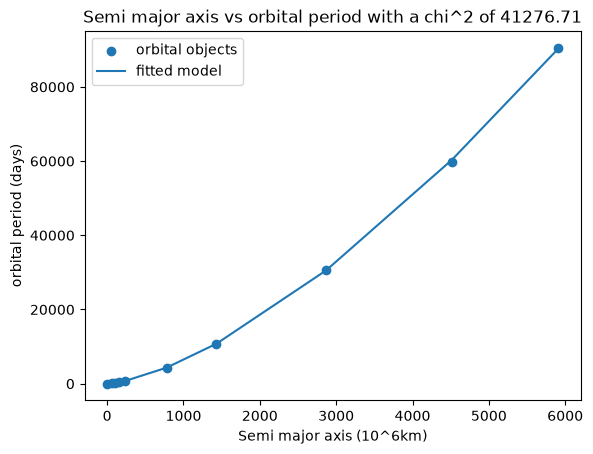

In [13]:
plt.figure()
plt.scatter(semimajoraxis, orbitalperiod, label = "orbital objects")
plt.plot(semimajoraxis, keplers_third_law(semimajoraxis, m_fit), label = "fitted model")
plt.title("Semi major axis vs orbital period with a chi^2 of 41276.71")
plt.xlabel("Semi major axis (10^6km)")
plt.ylabel("orbital period (days)")
plt.legend()
plt.show()

In [14]:
df.to_csv("kepler.csv", index=False)
